# Lesson 2 — The reliability index and FORM

A limit state function $g(\mathbf X)$ separates safe ($g > 0$) from failed
($g \le 0$) states. The probability of failure is

$$ P_f = P[g(\mathbf X) \le 0] = \int_{g \le 0} f_{\mathbf X}(\mathbf x)\,d\mathbf x , $$

an integral nobody wants to evaluate directly. The **first-order
reliability method (FORM)** replaces it by a geometric problem: in the
space of independent standard-normal variables $\mathbf U$, find the point
of the failure surface $g(\mathbf u) = 0$ that is closest to the origin —
the *design point* $\mathbf u^*$. Its distance

$$ \beta = \lVert \mathbf u^* \rVert, \qquad P_f \approx \Phi(-\beta) $$

is the **reliability index** that the Eurocodes use as the target
($\beta_t = 3.8$ for 50 years, consequence class 2).

This lesson works through two-variable examples so that every step can
be drawn.

In [1]:
import os
import sys

import numpy as np
from scipy.special import ndtr

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('..'))
    import codecal as cc
from codecal import plots
from codecal.plots import Figure

FIG = 'figures'
os.makedirs(FIG, exist_ok=True)


def save(fig, name):
    """Save a figure next to the lesson and show it (inline in Jupyter/Spyder)."""
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')
    try:
        from IPython.display import display
        display(fig)
    except ImportError:            # plain python: the PNG in figures/ is the output
        pass

## 1. The problem: $g = R - S$

$R$: lognormal, mean 2.6, CoV 0.15 (a resistance including its model
uncertainty). $S$: Gumbel, mean 1.0, CoV 0.30 (the 50-year maximum of a
load effect). The mean safety margin is 2.6 — but how safe is that?

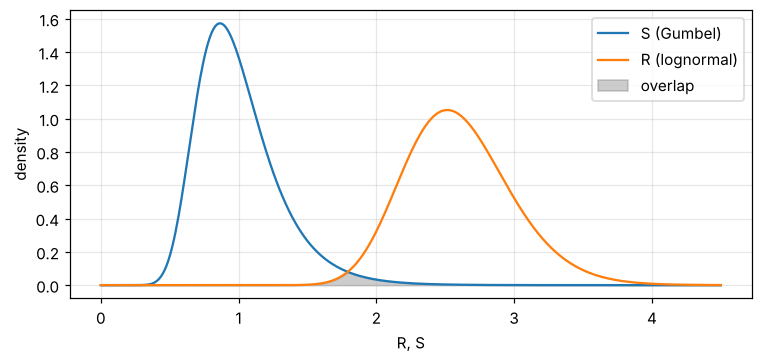

In [2]:
R = cc.rv('R', 'lognormal', 2.6, 0.15, char=1.0)
S = cc.rv('S', 'gumbel', 1.0, 0.30, char=1.0)
ls = cc.LimitState(lambda x: x[0] - x[1], [R, S], name='R − S')

x = np.linspace(0, 4.5, 400)
fig = Figure(figsize=(8, 3.4))
ax = fig.subplots()
ax.plot(x, S.dist.pdf(x), label='S (Gumbel)')
ax.plot(x, R.dist.pdf(x), label='R (lognormal)')
ax.fill_between(x, np.minimum(S.dist.pdf(x), R.dist.pdf(x)), color='grey', alpha=0.4, label='overlap')
ax.set_xlabel('R, S')
ax.set_ylabel('density')
ax.legend()
ax.grid(alpha=0.3)
save(fig, 'lesson02_R_S.png')

## 2. Brute force first: Monte Carlo

Draw $R$ and $S$ a few million times and count how often $R \le S$. The
standard error tells how much the estimate scatters: for $\beta \approx 3$
($P_f \approx 10^{-3}$) one needs millions of samples for two decimals
of $\beta$ — and for $\beta = 3.8$ a hundred times more.

In [3]:
mc = cc.monte_carlo(ls, n=4_000_000, seed=1)
print(f"Monte Carlo: P_f = {mc.pf:.3e}  ({mc.failures:.0f} failures in {mc.n:,} samples)")
print(f"             β   = {mc.beta:.3f} ± {mc.se_beta:.3f}")

Monte Carlo: P_f = 1.821e-03  (7283 failures in 4,000,000 samples)
             β   = 2.908 ± 0.004


## 3. FORM: the design point by the HL-RF iteration

`cc.form` implements the Hasofer–Lind / Rackwitz–Fiessler iteration:
linearise $g$ at the current point, jump to the design point of the
linearised surface, repeat. Each step needs $g$ and its gradient in
$u$-space; the gradient is obtained by the chain rule,
$\partial g/\partial u_i = \partial g/\partial x_i \cdot dx_i/du_i$
(numerically here — pass `grad=` for an analytic one).

FORM: β = 2.9027, P_f ≈ 1.850e-03, 6 iterations, converged=True
      design point u* = [-1.22   2.634],  x* = [2.143 2.143]
      α = [-0.42   0.907]   α² = {'R': 0.1766, 'S': 0.8234}


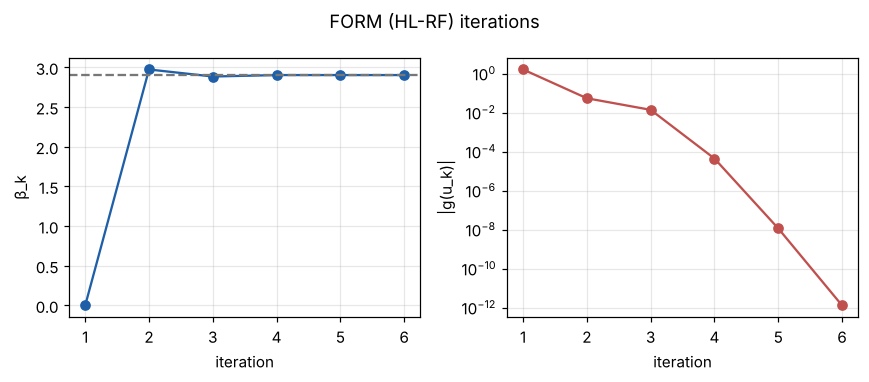

In [4]:
res = cc.form(ls)
print(f"FORM: β = {res.beta:.4f}, P_f ≈ {res.pf:.3e}, {res.iterations} iterations, converged={res.converged}")
print(f"      design point u* = {res.u_star.round(3)},  x* = {res.x_star.round(3)}")
print(f"      α = {res.alpha.round(3)}   α² = {res.sensitivities(['R', 'S'])}")
save(plots.plot_form_history(res), 'lesson02_form_history.png')

FORM agrees with the Monte-Carlo estimate within its standard error. The
picture shows why: in $u$-space the failure surface of $R - S$ is almost
a straight line, so the linearisation at the design point loses nothing.

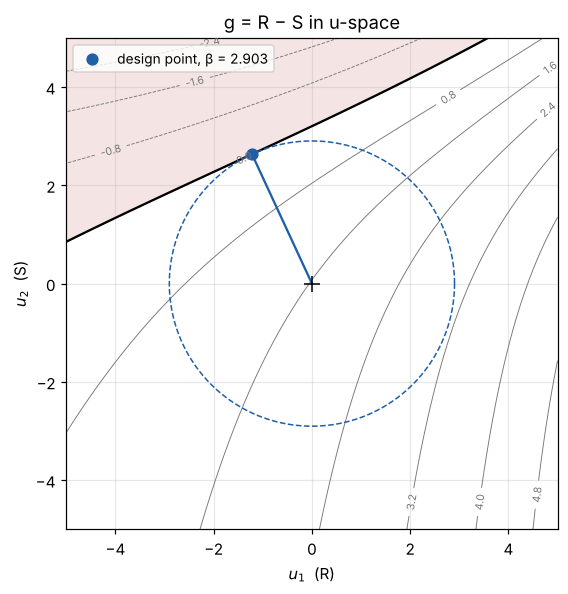

In [5]:
save(plots.plot_limit_state_2d(ls, res, lim=5, title='g = R − S in u-space'), 'lesson02_u_space.png')

The red region is failure, the black line the limit state $g = 0$, the
dashed circle has radius $\beta$. The design point is the point of the
failure region closest to the origin, i.e. the *most likely failure
scenario*: $x^*$ tells you with which values of $R$ and $S$ the
structure fails most probably.

## 4. Sensitivities: who is responsible?

$\alpha = u^*/\beta$ is a unit vector; $\alpha_i^2$ is the share of
variable $i$ in the uncertainty at the design point, and its sign says
whether it acts as a resistance ($\alpha < 0$) or as a load ($\alpha > 0$).
Here $S$ dominates. Eurocode's **design-value format** builds directly
on this: the design value of each variable is

$$ x_d = F^{-1}\big(\Phi(\alpha\,\beta)\big) , $$

and with *fixed* sensitivities $\alpha_R = -0.8$, $\alpha_E = 0.7$ (EN 1990,
Annex C) one obtains partial factors $\gamma = x_d / x_k$ without running
FORM at all. Code calibration is the step that checks, over many
structures, how good such fixed values are.

In [6]:
for v, a in zip(ls.variables, res.alpha):
    xd = v.dist.ppf(ndtr(a * res.beta))
    print(f"  {v.name}: α = {a:+.3f},  design value x_d = F⁻¹(Φ(α β)) = {xd:.3f}  (x* = {v.x_of_u(a * res.beta):.3f})")

  R: α = -0.420,  design value x_d = F⁻¹(Φ(α β)) = 2.143  (x* = 2.143)
  S: α = +0.907,  design value x_d = F⁻¹(Φ(α β)) = 2.143  (x* = 2.143)


## 5. When the surface is curved: SORM and importance sampling

Now a limit state with the structure of the calibration problem: a load
effect that is the *product* of a model uncertainty $\Theta$ (lognormal,
CoV 0.26 — the wind value of the AHG model) and a load $Q$ (Gumbel, CoV
0.14), against a fixed resistance 2.4:

$$ g = 2.4 - \Theta\,Q . $$

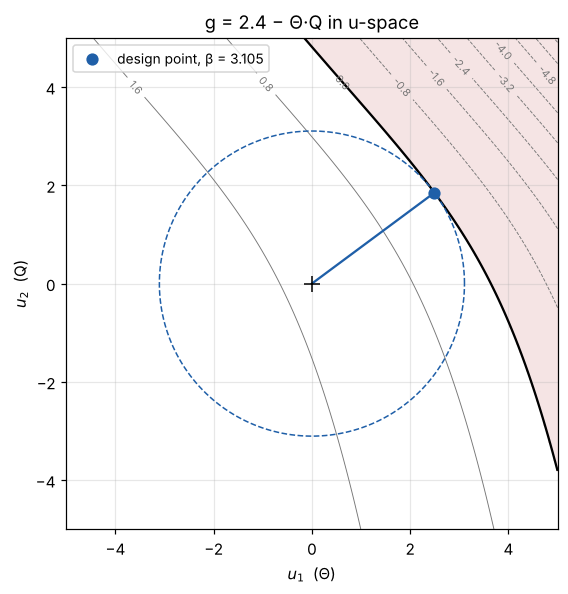

In [7]:
theta = cc.rv('Θ', 'lognormal', 1.0, 0.26, char=1.0)
Q = cc.rv('Q', 'gumbel', 1.0, 0.14, char=1.0)
ls2 = cc.LimitState(lambda x: 2.4 - x[0] * x[1], [theta, Q], name='2.4 − Θ·Q')
res2 = cc.form(ls2)
save(plots.plot_limit_state_2d(ls2, res2, lim=5, title='g = 2.4 − Θ·Q in u-space'), 'lesson02_u_space_product.png')

The failure surface bends *towards* the origin on both sides of the
design point: the failure domain is larger than FORM's half-space and
FORM is optimistic. Two cheap ways to check and improve it:

* **SORM** (Breitung) corrects for the main curvatures $\kappa_i$ of the
  surface at the design point: $P_f \approx \Phi(-\beta)\prod_i (1 + \beta\kappa_i)^{-1/2}$.
* **Importance sampling** draws samples *around the design point* and
  re-weights them; a few thousand samples give what crude Monte Carlo
  needs millions for.

In [8]:
b_sorm, kappa = cc.sorm(ls2, res2)
isr = cc.importance_sampling(ls2, res2, n=50_000, seed=1)
mc2 = cc.monte_carlo(ls2, n=4_000_000, seed=1)
print(f"FORM                 β = {res2.beta:.4f}")
print(f"SORM (κ = {kappa.round(4)})  β = {b_sorm:.4f}")
print(f"importance sampling  β = {isr.beta:.4f} ± {isr.se_beta:.4f}  ({isr.n:,} samples)")
print(f"crude Monte Carlo    β = {mc2.beta:.4f} ± {mc2.se_beta:.4f}  ({mc2.n:,} samples)")

FORM                 β = 3.1052
SORM (κ = [-0.063])  β = 3.0729
importance sampling  β = 3.0733 ± 0.0025  (50,000 samples)
crude Monte Carlo    β = 3.0753 ± 0.0046  (4,000,000 samples)


SORM and importance sampling agree with the expensive Monte-Carlo
estimate; FORM alone is about 0.035 too high. Keep that number in mind —
the calibration limit state of the next lessons contains exactly this
product, and the same bias (lesson 6 quantifies it over the whole model).

## 6. How β depends on the safety margin

Finally the relation a code writer cares about: how much mean resistance
buys how much reliability. Scaling $R$ by a factor $z$ — exactly what a
partial factor does — moves $\beta$:

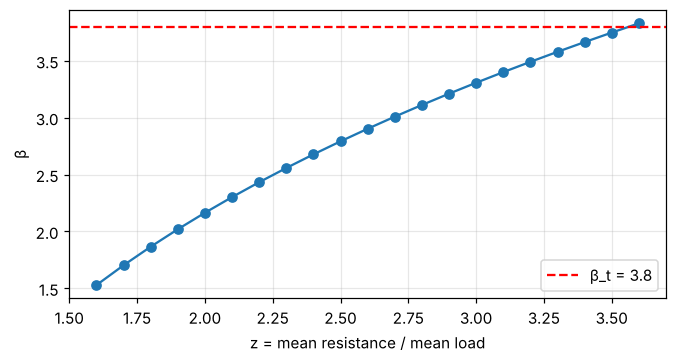

z needed for β = 3.8: ≈ 3.56


In [9]:
zs = np.linspace(1.6, 3.6, 21)
betas = []
for z in zs:
    ls_z = cc.LimitState(lambda x, z=z: z * x[0] - x[1],
                         [cc.rv('R', 'lognormal', 1.0, 0.15, char=1.0), S])
    betas.append(cc.form(ls_z).beta)
fig = Figure(figsize=(7, 3.4))
ax = fig.subplots()
ax.plot(zs, betas, 'o-')
ax.axhline(3.8, color='r', ls='--', label='β_t = 3.8')
ax.set_xlabel('z = mean resistance / mean load')
ax.set_ylabel('β')
ax.grid(alpha=0.3)
ax.legend()
save(fig, 'lesson02_beta_vs_z.png')
print(f"z needed for β = 3.8: ≈ {np.interp(3.8, betas, zs):.2f}")

## Exercises

1. Replace the Gumbel load by a normal one with the same mean and CoV.
   How do β and the FORM–Monte-Carlo gap change? Look at the u-space plot.
2. Make $R$ the dominant variable (CoV 0.30) and $S$ a small one (CoV 0.10).
   What happens to $\alpha$? Compare with the EN 1990 values −0.8 / 0.7.
3. Write the gradient of $g = R - S$ analytically and pass it as `grad=`
   to `LimitState`; check that the design point is unchanged.
4. In section 5, replace the fixed resistance 2.4 by a lognormal $R$
   (mean 2.4, CoV 0.10). Does the FORM bias grow or shrink?